アクション: 0
現在の状態: (0, 1)
Qテーブル:
 [[[-0.1  0. ]
  [ 0.   0. ]
  [ 0.   0. ]]]
アクション: 0
現在の状態: (0, 2)
Qテーブル:
 [[[-0.1  0. ]
  [10.   0. ]
  [ 0.   0. ]]]
ゴール
アクション: 1
現在の状態: (0, 0)
Qテーブル:
 [[[-0.1 -0.1]
  [10.   0. ]
  [ 0.   0. ]]]
アクション: 0
現在の状態: (0, 1)
Qテーブル:
 [[[ 0.71 -0.1 ]
  [10.    0.  ]
  [ 0.    0.  ]]]
アクション: 0
現在の状態: (0, 2)
Qテーブル:
 [[[ 0.71 -0.1 ]
  [19.    0.  ]
  [ 0.    0.  ]]]
ゴール
アクション: 0
現在の状態: (0, 1)
Qテーブル:
 [[[ 2.249 -0.1  ]
  [19.     0.   ]
  [ 0.     0.   ]]]
アクション: 0
現在の状態: (0, 2)
Qテーブル:
 [[[ 2.249 -0.1  ]
  [27.1    0.   ]
  [ 0.     0.   ]]]
ゴール
アクション: 0
現在の状態: (0, 1)
Qテーブル:
 [[[ 4.3631 -0.1   ]
  [27.1     0.    ]
  [ 0.      0.    ]]]
アクション: 0
現在の状態: (0, 2)
Qテーブル:
 [[[ 4.3631 -0.1   ]
  [34.39    0.    ]
  [ 0.      0.    ]]]
ゴール
アクション: 0
現在の状態: (0, 1)
Qテーブル:
 [[[ 6.92189 -0.1    ]
  [34.39     0.     ]
  [ 0.       0.     ]]]
アクション: 0
現在の状態: (0, 2)
Qテーブル:
 [[[ 6.92189 -0.1    ]
  [40.951    0.     ]
  [ 0.       0.     ]]]
ゴール
アクション: 1
現在の状態: (0, 0)
Qテーブル:
 [[[ 

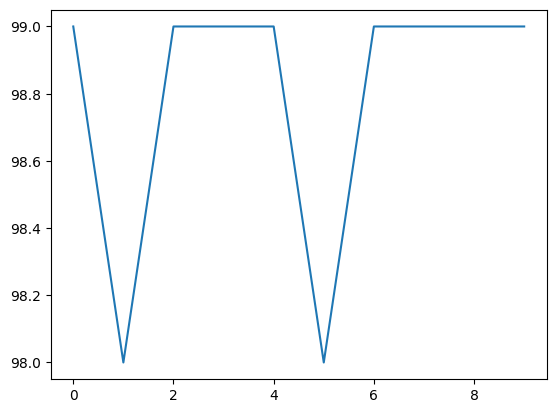

In [3]:
import numpy as np
#Pythonで数値計算ライブラリを使う
import matplotlib.pyplot as plt
#描画ライブラリ

# 迷路の設定
maze = np.array([[0,0,0]])

#定数の定義

#エージェントが探索する最初の地点(0行目、0列目）を指定
START=(0,0)
#エージェントが目指すゴール地点の座標（0行目、2列目）を指定
GOAL=(0,2)
#ゴールに到達したときに与えられるプラスの報酬（ご褒美）大きい値ほどここを目指すようになる
REWARD_GOAL=100
#1歩移動するごとに与えられるマイナスの報酬（ペナルティ）遠回りするほどペナルティがかかるため最短経路にいくように学習する役割をになう
REWARD_STEP=-1
#学習率です。新しく得た経験（報酬）を、これまでのQ値（行動の価値）にどのくらいの割合で反映させるかを決めます（0.1なら10%ずつ更新）。
ALPHA = 0.1
#割引率です。目先の報酬だけでなく、「将来もらえるであろう報酬」をどれくらい重視するかを決めます（1に近いほど未来の大きな報酬を重視）。
GAMMA = 0.9
#探索率です（ε-greedy法で使用）。「これまでに学習したベストな行動」ではなく、「あえてランダムな行動をとって新しいルートを試す確率」を指定（0.1なら10%の確率でランダム行動）。
EPSILON = 0.1
#学習の試行回数（エピソード数）です。「スタートからゴール（または終了条件）まで」の1プレイを1エピソードとし、それを合計10回繰り返して学習することを指定
EPISODES = 10

# Qテーブルの初期化
#①np.zeros(...)は指定したサイズで、すべての要素が 0 の NumPy 配列を作成
#②maze.shape[0] と maze.shape[1]でmaze（迷路のデータ）の縦の行数と横の列数を取得
#③各マス（状態）においてエージェントが選べる「行動（アクション）の数」を表す。このコードの場合、選べる行動が「2種類」（例：右と左、進むと戻る など）あることを意味する。
q_table = np.zeros((maze.shape[0], maze.shape[1], 2))

# 行動の設定（右、左）
actions = [(0, 1), (0, -1)]

#エージェントの状態に応じた行動を関数にする（引数は状況（環境から与えられている状況））
def choose_action(state):
  #ランダムに行動するかどうかを判定する条件分岐(np.random.uniform(0, 1) は、0 から 1 までの間のランダムな数値を一様に発生させる)
  if np.random.uniform(0,1)<EPSILON:
   #全行動の総数を取得し、その中からランダムに1つの行動を等確率で選んで返す。
    return np.random.choice(len(actions))
  else:
    #その中で最も値が大きいい（最も報酬が期待できる）行動のインデックスを返す。これにより、これまで学習した中で一番良いとされている行動を選択。
    return np.argmax(q_table[state])

# 次の状態に移る関数（引数として state（現在の位置）と、action（どの方向にどれだけ動くかを表す移動量））
def next_state(state, action):
  #現在の座標に移動量を足し合わせて、移動先の仮の座標（next_st）を計算。
  next_st = (state[0] + action[0], state[1] + action[1])
  #移動先の列（横方向のインデックス）が、迷路の範囲内に収まっているか
  if 0 <= next_st[1] < maze.shape[1]:
    #範囲内（移動可能）であれば、新しい座標（next_st）を返す
    return next_st
  else:
    #範囲内（移動可能）であれば、元の位置（state）を返す
    return state


 # Qテーブルの更新（引数として現在の状態（state）、選択した行動（action）、得られた報酬（reward）、移動先の次の状態（next_state））
def update_q_table(state, action, reward, next_state):
  #次の状態（next_state）において、Qテーブルに記録されている価値（Q値）の中で最も値が大きい（＝最適と予測される）行動のインデックスを np.argmax で探して取得
  best_next_action = np.argmax(q_table[next_state])
  #次の状態における最大Q値に、割引率（GAMMA, $\gamma$）を掛け合わせて「将来の価値の予測値（TDターゲット）」を計算
  td_target = GAMMA * q_table[next_state][best_next_action]
  #先ほど計算した td_target から、現在の状態と行動における現在のQ値（q_table[state][action]）を引くことで、「予測値と現在値のズレ（誤差）」を求める
  td_error = td_target - q_table[state][action]
  #Qテーブルの更新
  q_table[state][action] += ALPHA * (td_error + reward)


#Q学習
#各エピソードで得られた合計報酬を記録しておくためのリスト
rewards = []
#学習の試行回数（エピソード数）の分だけ繰り返す。
for episode in range(EPISODES):
  #エピソードの開始時に、エージェントの位置を「スタート地点（START）」にリセット
  state = START
  #そのエピソード内で獲得した報酬の合計をリセット
  total_reward = 0
  #エージェントがゴール（GOAL）にたどり着くまで、1ステップずつの行動を繰り返す
  while state != GOAL:
    #現在の状態（state）において、どの行動を選ぶかを決定
    action = choose_action(state)
    #選んだ行動を実行した結果、次に移動する状態（next_st）を計算・取得
    next_st = next_state(state, actions[action])
    #次の状態がゴールであれば、大きな報酬（REWARD_GOAL、例: +100など）を与える。
    if next_st == GOAL:
      reward = REWARD_GOAL
    #ゴールでなければ、移動コストやペナルティとなる小さな報酬を与える
    else:
      reward = REWARD_STEP
    #先ほど解説した関数を呼び出し、今回の「状態・行動・報酬・次の状態」を元に、Qテーブルの値を更新
    update_q_table(state, action, reward, next_st)
    #エージェントの現在地を次の状態に更新し、次のループへ
    state = next_st
     #今回のステップで得た報酬を、エピソード全体の合計報酬に加算
    total_reward += reward
    print("アクション:", action)
    print("現在の状態:", state)
    print("Qテーブル:\n", q_table)
  #そのエピソードで得られた合計報酬をリストに保存
  rewards.append(total_reward)
  print("ゴール")

# 横軸にエピソード番号（0からEPISODES-1まで）、縦軸にそのエピソードでの総報酬をとった折れ線グラフを作成する
plt.plot(range(EPISODES), rewards)
#結果を表示
plt.show()






## Q学習における迷路最適ルート

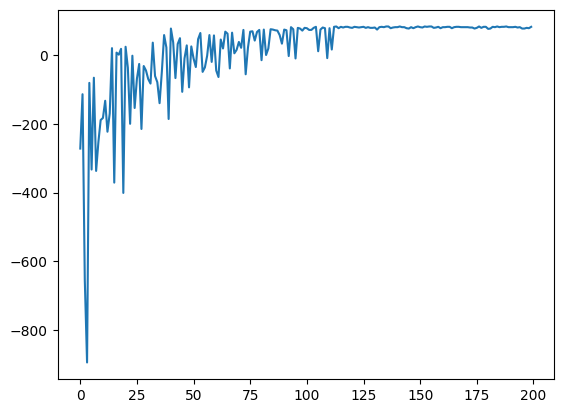

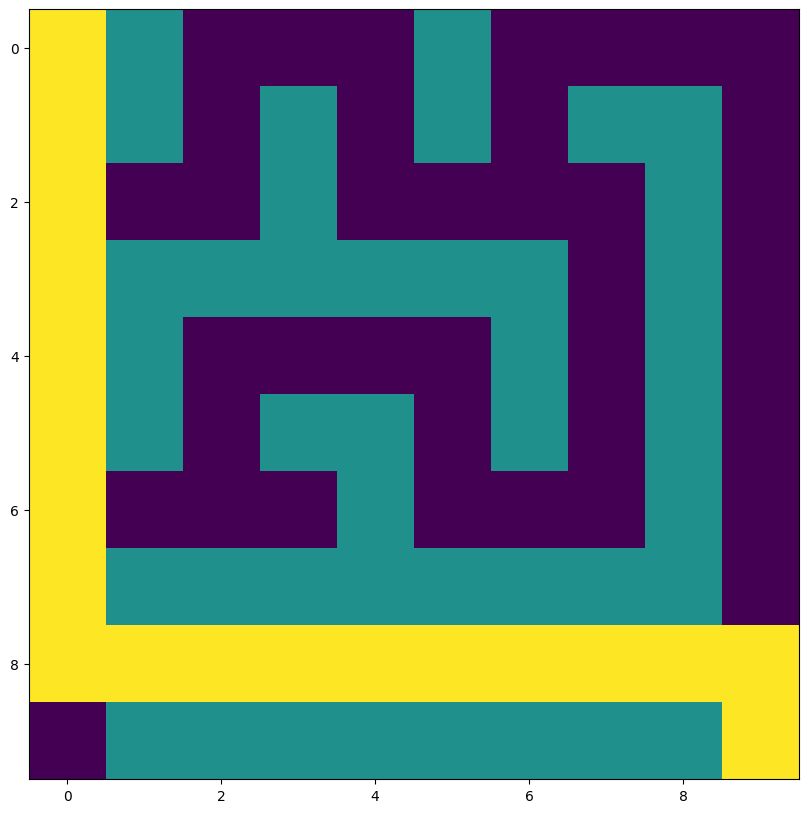

[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (8, 1), (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (8, 8), (8, 9), (9, 9)]


In [8]:
import numpy as np
# 数値計算を効率的に行うためのNumPyライブラリをインポートする
import matplotlib.pyplot as plt
 # グラフを描画するためのmatplotlib.pyplotモジュールをインポートする
import matplotlib.colors as mcolors
 # グラフのカラーマップを操作するためのモジュールをインポートする


# 0を通路、1を壁とした10×10の迷路の構造をNumPy配列として定義する
maze = np.array([
    [0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 0, 1, 0, 1, 1, 0],
    [0, 0, 0, 1, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0, 1, 0],
    [0, 1, 0, 0, 0, 0, 1, 0, 1, 0],
    [0, 1, 0, 1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 0]
    ])

# エージェントのスタート位置を座標 (0, 0) に設定する
START = (0, 0)
# エージェントのゴール位置を座標 (9, 9) に設定する
GOAL = (9, 9)
# ゴールに到達したときに与える報酬の値を設定する
REWARD_GOAL = 100
# 移動するたびに（ゴール以外で）与えるペナルティ（負の報酬）を設定する
REWARD_STEP = -1
# Q学習の学習率（Alpha）を設定する（新しい情報をどれくらい強く反映させるか）
ALPHA = 0.1
# 割引率（Gamma）を設定する（将来の報酬をどれくらい重視するか）
GAMMA = 0.9
# ε-greedy法における、ランダムに行動を選択する確率（イプシロン）を設定する
EPSILON = 0.1
# 学習を行うエピソード（試行回数）の総数を設定する
EPISODES = 200

# 迷路の各マスにおける4方向（上下左右）の価値を保存するQテーブルを0で初期化する
q_table = np.zeros((maze.shape[0], maze.shape[1], 4))

# エージェントが移動できる4つの方向（上、右、下、左）の座標移動量を定義する
actions = [(-1, 0), (0, 1), (1, 0), (0, -1)]

# ε-greedy法に基づき、現在の状態における次の行動（インデックス）を選択する関数を定義する
def choose_action(state):
    # ランダムな値がイプシロン未満の場合は、探索としてランダムな行動を選択する
    if np.random.uniform(0, 1) < EPSILON:
        return np.random.choice(len(actions))
    # そうでない場合は、Qテーブルに基づいて最も価値の高い（Q値が最大の）行動を選択する
    else:
        return np.argmax(q_table[state])

# 現在の状態と選択した行動から、次の状態を計算して返す関数を定義する
def next_state(state, action):
    # 移動後の仮の座標を計算する
    next_st = (state[0] + action[0], state[1] + action[1])
    # 移動先が迷路の範囲内かつ通路（0）であるかどうかを判定する
    if 0 <= next_st[0] < maze.shape[0] and 0 <= next_st[1] < maze.shape[1] and maze[next_st] == 0:
        return next_st  # 移動可能であれば移動後の座標を返す
    else:
        return state  # 移動不可能（壁や範囲外）であれば元の状態のままにする

# ベルマン方程式に基づいてQテーブルの値を更新する関数を定義する
def update_q_table(state, action, reward, next_state):
    # 次の状態において最も価値の高い行動のインデックスを取得する
    best_next_action = np.argmax(q_table[next_state])
    # TDターゲット（割引率 × 次の状態の最大Q値）を計算する
    td_target = GAMMA * q_table[next_state][best_next_action]
    # TD誤差（目標値と現在のQ値の差）を計算する
    td_error = td_target - q_table[state][action]
    # 学習率とTD誤差・報酬を用いてQテーブルの該当要素を更新する
    q_table[state][action] += ALPHA * (td_error + reward)

# 各エピソードでの総報酬を記録するためのリストを初期化する
rewards = []
# 指定されたエピソード数だけ強化学習のループを回す
for episode in range(EPISODES):
    # 各エピソードの開始時に状態をスタート位置にリセットする
    state = START
    # そのエピソードでの総報酬を0に初期化する
    total_reward = 0
    # エージェントがゴールに到達するまでループを続ける
    while state != GOAL:
        # 現在の状態における行動を選択する
        action = choose_action(state)
        # 選択した行動によって次の状態を決定する
        next_st = next_state(state, actions[action])
        # 次の状態がゴールであるかどうかで報酬の値を切り替える
        if next_st == GOAL:
            reward = REWARD_GOAL
        else:
            reward = REWARD_STEP
        # 経験に基づいてQテーブルを更新する
        update_q_table(state, action, reward, next_st)
        # 現在の状態を次の状態に更新する
        state = next_st
        # 獲得した報酬を累積する
        total_reward += reward
    # エピソードごとの総報酬をリストに記録する
    rewards.append(total_reward)

# 学習経過（エピソードごとの総報酬の変化）を折れ線グラフとしてプロットする
plt.plot(range(EPISODES), rewards)
# プロットしたグラフを表示する
plt.show()

# 学習完了後、スタートからゴールまでの最適な経路を求めるため、初期状態を設定する
state = START
# 最適経路を記録するリストにスタート位置を追加する
path = [state]
# ゴールに到達するまで最適な行動を辿るループを回す
while state != GOAL:
    # Qテーブルから最も価値の高い行動を選択する
    action = np.argmax(q_table[state])
    # その行動に従って次の状態に移動する
    state = next_state(state, actions[action])
    # 移動した座標を最適経路リストに追加する
    path.append(state)

# 迷路の配列をコピーし、経路を描画用のデータに加工する準備をする
maze_with_path = maze.copy()
# 求めた最適経路上のマスの値を「2」に変更する（可視化の際に色を変えるため）
for i in path:
    maze_with_path[i] = 2

# グラフの描画サイズを10×10インチに設定する
plt.figure(figsize=[10, 10])
# 迷路と最適経路を画像としてプロットする
plt.imshow(maze_with_path)
# 描画した画像を表示する
plt.show()

# 最終的な最適経路の座標リストをコンソールに出力する
print(path)